# Company A | Churn prediction and retention business case

**Author:** NaderElmekawy

## 1. Business question and data

Can Company A prioritize customers with a high probability of churning 31–60 days after the observation date? The dataset overview defines `churn` as churn within that period. Market evidence is context, not a forecast for Company A.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve
from sklearn.inspection import permutation_importance

In [8]:

from google.colab import drive


drive.mount("/content/drive")

data_dir = Path(
    "/content/drive/.shortcut-targets-by-id/1ek_ShgcTnnMu9Am_3HvdGMYohoX5A9tv/"
    "GCI World_202609/05. Final Assignment (due Nov 28)/"
    "Final Assignment/telecom"
)

client_path = data_dir / "Client.csv"
record_path = data_dir / "Record.csv"

if not client_path.is_file() or not record_path.is_file():
    raise FileNotFoundError("Dataset files not found.")

client = pd.read_csv(client_path)
record = pd.read_csv(record_path)

df = record.merge(
    client,
    on="Customer_ID",
    validate="one_to_one"
)

print("Client:", client.shape)
print("Record:", record.shape)
print("Merged dataset:", df.shape)
print("Unique customers:", df["Customer_ID"].nunique())
print("Churn rate:", round(df["churn"].mean() * 100, 2), "%")

display(df.head())


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Client: (100000, 50)
Record: (100000, 51)
Merged dataset: (100000, 100)
Unique customers: 100000
Churn rate: 49.56 %


,rev_Mean,mou_Mean,totmrc_Mean,da_Mean,ovrmou_Mean,ovrrev_Mean,vceovr_Mean,datovr_Mean,roam_Mean,change_mou,...,dwllsize,forgntvl,ethnic,kid0_2,kid3_5,kid6_10,kid11_15,kid16_17,creditcd,eqpdays
0,23.9975,219.25,22.500,0.2475,0.00,0.0,0.0,0.0,0.0,-157.25,...,A,0.0,N,U,U,U,U,U,Y,361.0
1,57.4925,482.75,37.425,0.2475,22.75,9.1,9.1,0.0,0.0,532.25,...,A,0.0,Z,U,U,U,U,U,Y,240.0
2,16.9900,10.25,16.990,0.0000,0.00,0.0,0.0,0.0,0.0,-4.25,...,A,0.0,N,U,Y,U,U,U,Y,1504.0
3,38.0000,7.50,38.000,0.0000,0.00,0.0,0.0,0.0,0.0,-1.50,...,D,0.0,U,Y,U,U,U,U,Y,1812.0
4,55.2300,570.50,71.980,0.0000,0.00,0.0,0.0,0.0,0.0,38.50,...,O,0.0,I,U,U,U,U,U,Y,434.0


## 2. Exploratory analysis

The patterns below are associations, not causal effects.

Missing-value fractions:


,missing_fraction
numbcars,0.49366
dwllsize,0.38308
HHstatin,0.37923
ownrent,0.33706
dwlltype,0.31909
lor,0.30190
income,0.25436
adults,0.23019
infobase,0.22079
hnd_webcap,0.10189


Target balance:


,share
churn,
0,0.50438
1,0.49562


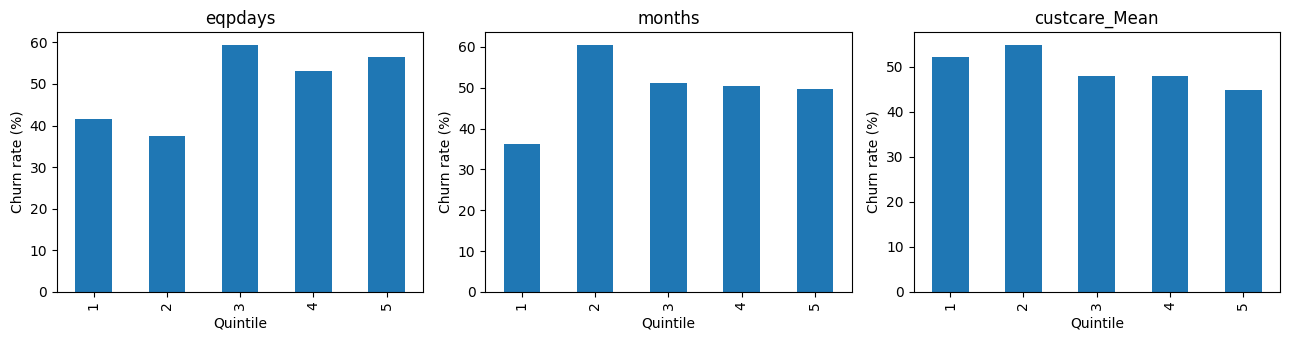

In [9]:
print("Missing-value fractions:")
display(df.isna().mean().sort_values(ascending=False).head(15).to_frame("missing_fraction"))
print("Target balance:")
display(df.churn.value_counts(normalize=True).rename("share").to_frame())
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, col in zip(axes, ["eqpdays", "months", "custcare_Mean"]):
    z = df[[col, "churn"]].dropna().copy()
    z["group"] = pd.qcut(z[col].rank(method="first"), 5, labels=False) + 1
    z.groupby("group").churn.mean().mul(100).plot.bar(ax=ax, title=col)
    ax.set_xlabel("Quintile")
    ax.set_ylabel("Churn rate (%)")
plt.tight_layout()
plt.show()

## 3. Modeling protocol

Use a stratified 75/25 development/test split. Split the development set again into 60% training and 15% validation. Select the model using validation ROC-AUC only, refit it on the full development set, and evaluate the held-out test set once.

In [10]:
features = [
    "rev_Mean", "mou_Mean", "totmrc_Mean", "ovrmou_Mean", "ovrrev_Mean",
    "change_mou", "change_rev", "drop_vce_Mean", "blck_vce_Mean",
    "drop_blk_Mean", "attempt_Mean", "complete_Mean", "custcare_Mean",
    "months", "uniqsubs", "actvsubs", "avgrev", "avg3rev", "avg6rev",
    "avg3mou", "avg6mou", "hnd_price", "eqpdays", "phones", "models", "totrev"
]
X = df[features].replace([np.inf, -np.inf], np.nan)
y = df.churn.astype(int)
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.20, random_state=42, stratify=y_dev
)
models = {
    "Logistic regression": make_pipeline(
        SimpleImputer(strategy="median"), StandardScaler(),
        LogisticRegression(max_iter=450, random_state=42)
    ),
    "Gradient boosting": make_pipeline(
        SimpleImputer(strategy="median"),
        HistGradientBoostingClassifier(
            max_iter=110, max_leaf_nodes=15, learning_rate=0.08, random_state=42
        )
    )
}
validation = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    score = model.predict_proba(X_val)[:, 1]
    top = score >= np.quantile(score, 0.80)
    validation[name] = {
        "ROC-AUC": roc_auc_score(y_val, score),
        "Average precision": average_precision_score(y_val, score),
        "Top-20% precision": y_val[top].mean(),
        "Top-20% recall": y_val[top].sum() / y_val.sum()
    }
display(pd.DataFrame(validation).T.round(4))
best_name = max(validation, key=lambda name: validation[name]["ROC-AUC"])
best_model = models[best_name]
print("Selected on validation:", best_name)

,ROC-AUC,Average precision,Top-20% precision,Top-20% recall
Logistic regression,0.6128,0.5844,0.6223,0.2511
Gradient boosting,0.6770,0.6580,0.7047,0.2844


Selected on validation: Gradient boosting


In [11]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(best_model, X_dev, y_dev, cv=cv, scoring="roc_auc", n_jobs=-1)
print(f"5-fold development ROC-AUC: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")
best_model.fit(X_dev, y_dev)
test_scores = best_model.predict_proba(X_test)[:, 1]
top20 = test_scores >= np.quantile(test_scores, 0.80)
test_metrics = {
    "ROC-AUC": roc_auc_score(y_test, test_scores),
    "Average precision": average_precision_score(y_test, test_scores),
    "Top-20% precision": y_test[top20].mean(),
    "Top-20% recall": y_test[top20].sum() / y_test.sum()
}
display(pd.Series(test_metrics).to_frame("held-out test"))

5-fold development ROC-AUC: 0.6763 ± 0.0021


,held-out test
ROC-AUC,0.674190
Average precision,0.660392
Top-20% precision,0.710000
Top-20% recall,0.286498


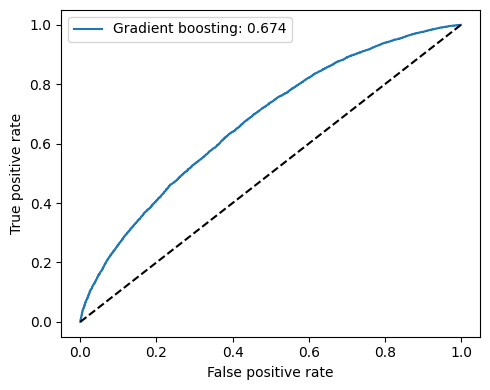

In [12]:
fpr, tpr, _ = roc_curve(y_test, test_scores)
plt.figure(figsize=(5, 4))
plt.plot(fpr, tpr, label=f"{best_name}: {test_metrics['ROC-AUC']:.3f}")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.legend()
plt.tight_layout()
plt.show()

In [13]:
rng = np.random.default_rng(42)
y_array = y_test.to_numpy()
predicted_top20 = top20
auc_boot, precision_boot = [], []
for _ in range(1000):
    sample = rng.integers(0, len(y_array), len(y_array))
    if np.unique(y_array[sample]).size < 2:
        continue
    auc_boot.append(roc_auc_score(y_array[sample], test_scores[sample]))
    selected = predicted_top20[sample]
    if selected.any():
        precision_boot.append(y_array[sample][selected].mean())
print("95% bootstrap CI, ROC-AUC:", np.quantile(auc_boot, [0.025, 0.975]).round(4))
print("95% bootstrap CI, top-20% precision:", np.quantile(precision_boot, [0.025, 0.975]).round(4))

95% bootstrap CI, ROC-AUC: [0.6674 0.6808]
95% bootstrap CI, top-20% precision: [0.6972 0.722 ]


In [14]:
test_results = df.loc[X_test.index, ["churn", "rev_Mean", "eqpdays", "months"]].copy()
test_results["risk"] = test_scores
test_results["risk_decile"] = pd.qcut(test_results.risk.rank(method="first"), 10, labels=False) + 1
display(test_results.groupby("risk_decile").agg(
    customers=("churn", "size"),
    churn_rate=("churn", "mean"),
    average_monthly_revenue=("rev_Mean", "mean")
).round(3))

,customers,churn_rate,average_monthly_revenue
risk_decile,,,
1,2500,0.218,53.689
2,2500,0.306,72.192
3,2500,0.403,67.020
4,2500,0.454,59.393
5,2500,0.498,57.212
6,2500,0.519,54.477
7,2500,0.555,54.921
8,2500,0.584,54.488
9,2500,0.656,57.343


In [15]:
age_score = X_test["eqpdays"].fillna(X_dev["eqpdays"].median())
age_top20 = age_score >= age_score.quantile(0.80)
print("Handset-age-only benchmark")
print("ROC-AUC:", round(roc_auc_score(y_test, age_score), 4))
print("Top-20% precision:", round(y_test[age_top20].mean(), 4))
print("Top-20% recall:", round(y_test[age_top20].sum() / y_test.sum(), 4))

Handset-age-only benchmark
ROC-AUC: 0.571
Top-20% precision: 0.5576
Top-20% recall: 0.2254


,mean_auc_decrease
eqpdays,0.047710
months,0.040266
mou_Mean,0.029370
change_mou,0.027720
avgrev,0.017186
totmrc_Mean,0.014175
hnd_price,0.012388
uniqsubs,0.009376
drop_vce_Mean,0.005959
avg6mou,0.004033


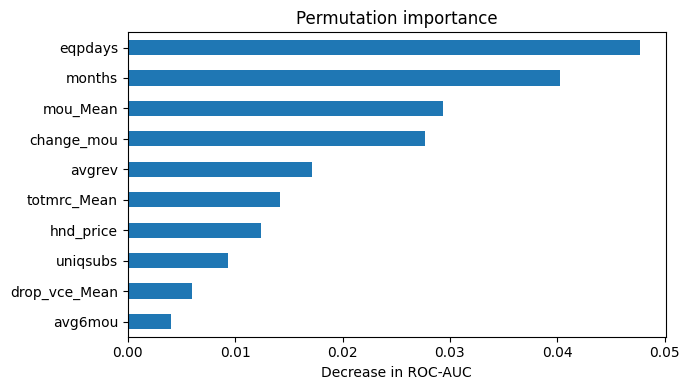

In [16]:
importance_sample = X_test.sample(n=10000, random_state=42)
importance = permutation_importance(
    best_model, importance_sample, y_test.loc[importance_sample.index],
    n_repeats=5, random_state=42, scoring="roc_auc", n_jobs=-1
)
importance_table = pd.Series(importance.importances_mean, index=features).sort_values(ascending=False)
display(importance_table.head(10).to_frame("mean_auc_decrease"))
importance_table.head(10).sort_values().plot.barh(figsize=(7, 4), title="Permutation importance")
plt.xlabel("Decrease in ROC-AUC")
plt.tight_layout()
plt.show()

## 4. Retention campaign and financial sensitivity

The scenario uses held-out top-20% precision and average monthly revenue for that same group. All monetary values are dataset units; the currency is not specified. The assumed save rate is not an observed treatment effect.

In [17]:
top_group = test_results.nlargest(int(len(test_results) * 0.20), "risk")
contacted = 20000
would_churn = contacted * top_group.churn.mean()
top_group_revenue = top_group.rev_Mean.clip(lower=0).mean()

def campaign_case(save_rate=0.10, margin=0.50, months=3, contact_cost=2, offer_cost=15):
    saved = would_churn * save_rate
    gross = saved * top_group_revenue * months * margin
    costs = contacted * contact_cost + saved * offer_cost
    return {
        "contacted": round(contacted),
        "would_churn_without_contact": round(would_churn),
        "saved_assumed": round(saved),
        "gross_contribution": round(gross),
        "campaign_cost": round(costs),
        "net_contribution": round(gross - costs)
    }

print("Top-20% average monthly revenue:", round(top_group_revenue, 2))
display(pd.DataFrame({
    f"save_{int(rate * 100)}%": campaign_case(save_rate=rate)
    for rate in [0.05, 0.10, 0.15]
}).T)

Top-20% average monthly revenue: 55.54


,contacted,would_churn_without_contact,saved_assumed,gross_contribution,campaign_cost,net_contribution
save_5%,20000,14200,710,59151,50650,8501
save_10%,20000,14200,1420,118303,61300,57003
save_15%,20000,14200,2130,177454,71950,105504


## 5. Proposed pilot and guardrails

- Run an 8-week randomized pilot with high-risk eligible customers assigned to outreach or business-as-usual.
- Measure 31–60 day churn and net incremental contribution after all costs.
- Validate label definitions, feature timing, eligibility rules and unit costs with Company A.
- Avoid treating predictive associations as causes.
- Restrict access to customer data and exclude sensitive demographic variables from the model.
- Revalidate on time-held-out data before deployment; the supplied extract has no date field.